# Notebook A: dữ liệu 2022–2024, làm sạch, lịch, SQL và RQ1

**Đề tài:** *What Each Data Repair Step Is Worth in Next-Hour Traffic Forecasting on the Istanbul Open Data and What Happens on Holidays*

**Phiên bản 2 (dữ liệu 2022–2024).** Năm 2022 dùng để chọn ô và huấn luyện; 8 quý của 2023–2024 lần lượt làm tập test ở Notebook B. Notebook này do Sinh viên A chạy từ trên xuống. Mỗi ô code có ô hướng dẫn phía trên gồm: **làm gì, vì sao, kiểm tra gì**.

| Sản phẩm bàn giao cho Notebook B | Nội dung |
|---|---|
| `data/processed/feat.parquet` | Bảng đặc trưng trên lưới giờ đầy đủ, tạo bằng SQL (LAG/LEAD) |
| `data/processed/traffic_raw.parquet` | Bản ghi thô của 150 ô (chưa sửa), dùng cho thang sửa dữ liệu ở RQ3 |
| `data/processed/traffic.parquet` | Bảng đã sửa đầy đủ (lưới giờ, cờ mất dữ liệu, lịch) |
| `data/processed/calendar_daily.parquet`, `city_hours.parquet` | Lịch theo ngày, số ô báo cáo theo giờ |
| `data/cells_selected.csv`, `data/dataset_inventory.csv` | Danh sách 150 ô, kiểm kê 36 file gốc |
| `data/processed/manifest.json` | Mã băm để Notebook B kiểm tra |

**Thời gian chạy dự kiến:** 15–30 phút (chủ yếu là đọc 36 file CSV, khoảng 4 GB). Các bước nặng có bộ nhớ đệm: chạy lại sẽ bỏ qua phần đã xong.

## Bước 0. Môi trường và cấu hình

- **Làm gì:** cài thư viện (một lần), khai báo cấu hình chung, mở kết nối DuckDB.
- **Vì sao:** mọi tham số quan trọng của bài (năm, số ô, ngưỡng độ phủ) nằm ở một chỗ để báo cáo và chạy lại.
- **Kiểm tra:** ô in ra cấu hình, không báo lỗi.
- **Vì sao 2022–2024:** cổng IBB hiện chỉ có dữ liệu đến 01/2025 (kiểm tra qua API ngày 07/10/2026), nên cửa sổ 3 năm đầy đủ gần nhất là 2022–2024.
- **Phương án dự phòng:** muốn chạy nhanh hơn thì đổi `YEARS = [2023, 2024]` và `SELECT_YEAR = 2023` (còn 4 quý test); không cần sửa chỗ nào khác.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm matplotlib scipy

In [2]:
import os, re, glob, json, hashlib, time, zipfile, shutil, urllib.request, warnings
from pathlib import Path
if Path.cwd().name == 'Source Code': os.chdir(Path.cwd().parent)          # notebooks live in 'Source Code/'; data/, report/ and sql/ are one level up
print('working folder:', Path.cwd())
from pathlib import Path
import numpy as np, pandas as pd, duckdb
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

YEARS = [2022, 2023, 2024]        # the portal has data up to 01/2025 only
SELECT_YEAR = 2022                # the 150 cells are chosen from this year only (no look at the test years)
N_CELLS = 150                     # busiest cells
MIN_COVERAGE = 0.5                # a cell must report at least half of the hours of SELECT_YEAR
AUTO_DOWNLOAD = True              # try the portal API first; manual download is described in Step 1a
BREAK_DATE = pd.Timestamp('2024-01-24')   # level break seen in the data (report only, see Step 2c.5)
FAULT_RATIO = 0.2                 # an hour is faulty when the city mean is below 20% of the same hour of the week in the 4 weeks around it
REBUILD = False                   # True: rebuild the cached parquet files from the CSV files

MONTHS = [f'{y}{m:02d}' for y in YEARS for m in range(1, 13)]
RAW, INTERIM, PROC, REPORT, SQLDIR = map(Path, ['data/raw', 'data/interim', 'data/processed', 'report', 'sql'])
for d in [RAW, INTERIM, PROC, REPORT, SQLDIR]: d.mkdir(parents=True, exist_ok=True)
CAL_FILE = Path('data/calendar_2022_2025.csv')
assert CAL_FILE.exists(), 'data/calendar_2022_2025.csv is missing: copy it from the project folder into data/'

con = duckdb.connect()
con.execute("SET memory_limit='3GB'"); con.execute(f"SET threads={max(1, (os.cpu_count() or 2) - 1)}")
con.execute(f"SET temp_directory='{(INTERIM / 'duckdb_tmp').as_posix()}'")
def q(sql): return con.execute(sql).df()           # run SQL, return a DataFrame
def save(df, name): df.to_csv(REPORT / name, index=False); return df
print('years', YEARS, '| months', len(MONTHS), '| select cells on', SELECT_YEAR, '| N_CELLS', N_CELLS, '| duckdb', duckdb.__version__, '| pandas', pd.__version__)

working folder: d:\Next-Hour Traffic Forecasting
years [2022, 2023, 2024] | months 36 | select cells on 2022 | N_CELLS 150 | duckdb 1.5.6 | pandas 3.0.6


### Hình quy trình nghiên cứu

- **Làm gì:** vẽ sơ đồ luồng của đề tài từ trái sang phải (không cần dữ liệu), chỉ giữ các nhánh quyết định kết quả: Open data (IBB, 36 file tháng, 58.4 triệu bản ghi, 2022–2024) → Data Preprocessing (150 ô đông nhất năm 2022, lưới giờ đầy đủ, lịch ngày lễ) → Time split (2022 chỉ để huấn luyện, 8 quý test 2023–2024) → 3 nhánh phân tích (Traffic patterns; Model comparison: 4 mô hình so với 3 mốc; Repair value: thang R0–R5 và lag tuần L0–L4) → Repair priorities.
- **Kiểm tra:** `report/fig_pipeline.png`.


findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

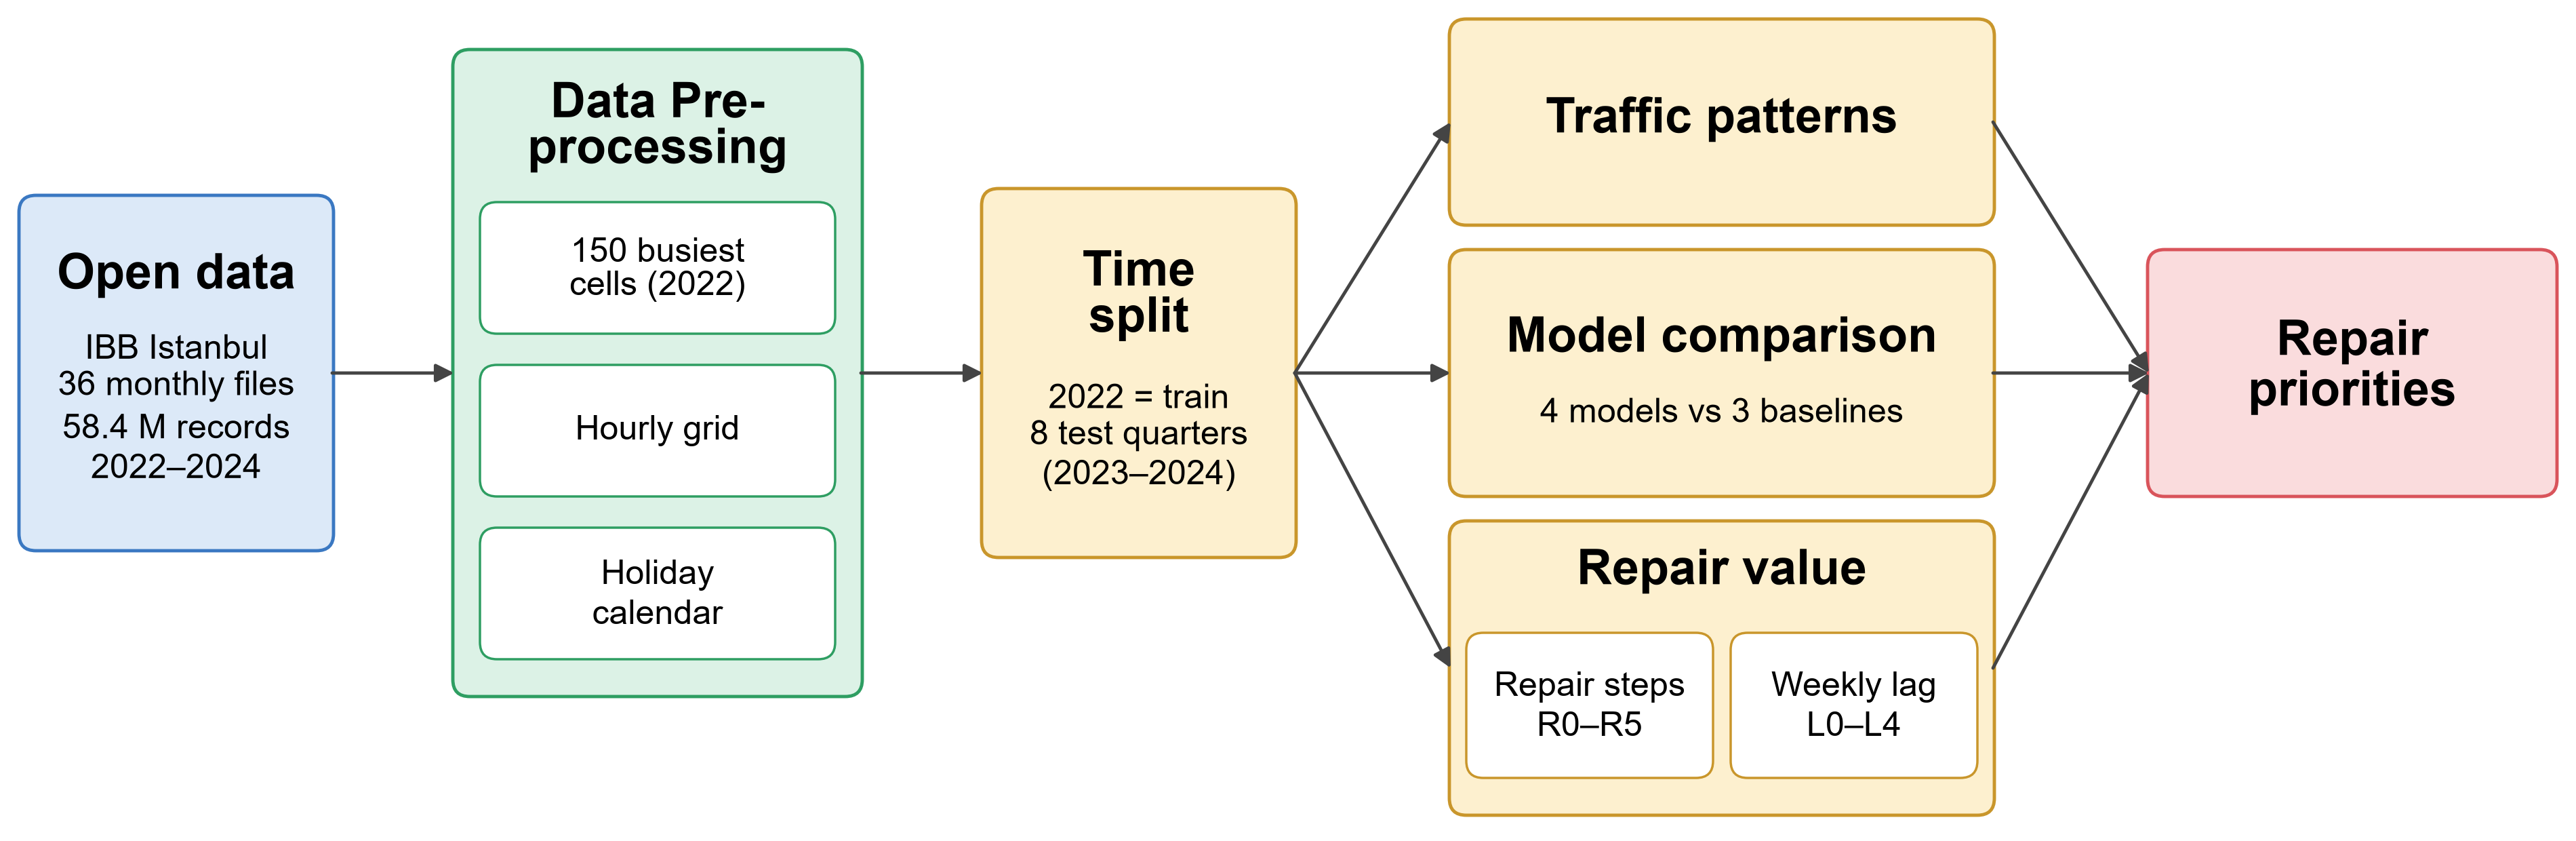

In [3]:
# Figure: pipeline of the study with the decisive sub-branches only, left to right (no data needed; every label restates a fact of the paper)
from matplotlib.patches import FancyBboxPatch
BLUE, GREEN, YELLOW, RED = ('#DCE9F8', '#3A78C2'), ('#DCF2E6', '#2E9E62'), ('#FDF0CF', '#C9962B'), ('#FADCDD', '#D9545B')
FF = ['Arial', 'Liberation Sans', 'DejaVu Sans']          # same letter widths on Windows (Arial) and Linux (Liberation Sans)
TS, BS = 52, 36                                         # font size of the box titles / of the detail lines
W_FIG, H_FIG = 37.8, 12.2                               # 1 unit = 1 inch, so text sizes and box sizes match
fig = plt.figure(figsize=(W_FIG, H_FIG)); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W_FIG); ax.set_ylim(-0.2, H_FIG - 0.2); ax.axis('off')
def rect(x0, y0, w, h, fc, ec, lw=3.5):
    ax.add_patch(FancyBboxPatch((x0, y0), w, h, boxstyle='round,pad=0.02,rounding_size=0.25', fc=fc, ec=ec, lw=lw))
def lines_h(s, size, ls): return (s.count('\n') + 1) * size / 72 * ls
def box(cx, cy, w, h, title, col, body='', left=False):
    rect(cx - w / 2, cy - h / 2, w, h, *col)
    th, bh = lines_h(title, TS, 1.15), (lines_h(body, BS, 1.25) if body else 0); gap = 0.3 if body else 0
    top = cy + (th + gap + bh) / 2
    ax.text(cx, top, title, ha='center', va='top', fontsize=TS, fontweight='bold', linespacing=1.1, fontfamily=FF)
    if body: ax.text(cx, top - th - gap, body, ha='center', va='top', fontsize=BS, linespacing=1.25, fontfamily=FF, multialignment='left' if left else 'center')
def group(x0, y0, w, h, title, col):                    # a box that holds smaller boxes (sub-steps)
    rect(x0, y0, w, h, *col)
    ax.text(x0 + w / 2, y0 + h - 0.35, title, ha='center', va='top', fontsize=TS, fontweight='bold', linespacing=1.1, fontfamily=FF)
def chip(cx, cy, w, h, text, col):
    rect(cx - w / 2, cy - h / 2, w, h, 'white', col[1], lw=2.5)
    ax.text(cx, cy, text, ha='center', va='center', fontsize=BS, linespacing=1.15, fontfamily=FF)
def arrow(x0, y0, x1, y1): ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', lw=3.5, color='#444444', mutation_scale=40, shrinkA=0, shrinkB=0))
Y = 6.6
# 1. open data
box(2.5, Y, 4.6, 5.2, 'Open data', BLUE, 'IBB Istanbul\n36 monthly files\n58.4 M records\n2022\u20132024')
# 2. pre-processing: cell selection and the two steps that drive the results (hourly grid, holiday calendar)
PX0, PW = 6.6, 6.0
group(PX0, Y - 4.75, PW, 9.5, 'Data Pre-\nprocessing', GREEN)
for yy, t in [(Y + 1.55, '150 busiest\ncells (2022)'), (Y - 0.85, 'Hourly grid'), (Y - 3.25, 'Holiday\ncalendar')]: chip(PX0 + PW / 2, yy, PW - 0.8, 1.9, t, GREEN)
# 3. time split
TX = 16.7
box(TX, Y, 4.6, 5.4, 'Time\nsplit', YELLOW, '2022 = train\n8 test quarters\n(2023\u20132024)')
# 4. three analyses; the repair analysis has two sub-branches
BX, BW = 25.3, 8.0
YT, YR = Y + 3.7, Y - 4.35                              # centres of the top box and of the repair group
box(BX, YT, BW, 3.0, 'Traffic patterns', YELLOW)
box(BX, Y, BW, 3.6, 'Model comparison', YELLOW, '4 models vs 3 baselines')
group(BX - BW / 2, YR - 2.15, BW, 4.3, 'Repair value', YELLOW)
for cx, t in [(BX - 1.95, 'Repair steps\nR0\u2013R5'), (BX + 1.95, 'Weekly lag\nL0\u2013L4')]: chip(cx, YR - 0.55, 3.6, 2.1, t, YELLOW)
# 5. conclusions
CX, CW = 34.6, 6.0
box(CX, Y, CW, 3.6, 'Repair\npriorities', RED)
# arrows
arrow(4.8, Y, PX0, Y); arrow(PX0 + PW, Y, TX - 2.3, Y)
for yy in [YT, Y, YR]: arrow(TX + 2.3, Y, BX - BW / 2, yy); arrow(BX + BW / 2, yy, CX - CW / 2, Y)
fig.savefig(REPORT / 'fig_pipeline.png', dpi=250, bbox_inches='tight', pad_inches=0.1); plt.show()


## Bước 1a. Lấy dữ liệu (36 file tháng, 2022–2024)

**Nguồn:** bộ *Hourly Traffic Density Data Set* của Istanbul Metropolitan Municipality (IBB), giấy phép dữ liệu mở, không cần tài khoản.

| | Đường dẫn |
|---|---|
| Trang bộ dữ liệu | https://data.ibb.gov.tr/en/dataset/hourly-traffic-density-data-set |
| API danh sách file (CKAN) | https://data.ibb.gov.tr/api/3/action/package_show?id=hourly-traffic-density-data-set |
| Ví dụ link tải trực tiếp (03/2024) | https://data.ibb.gov.tr/dataset/3ee6d744-5da2-40c8-9cd6-0e3e41f1928f/resource/b67e9415-0ba8-4319-8d36-359240a93808/download/traffic_density_202403.csv |

**Cách 1, tự động:** ô dưới gọi API, tìm file của từng tháng và tải về `data/raw/` (khoảng 4 GB, 30–60 phút tuỳ mạng). Ô **so dung lượng từng file với cổng**: file tải dở (bị ngắt giữa chừng) được đổi đuôi thành `.incomplete` và tải lại. Nếu bị ngắt, chỉ cần chạy lại ô này. Danh sách file của cổng được lưu ở `data/raw/resource_list.csv`.

**Cách 2, tải tay** (khi cách 1 lỗi hoặc thiếu tháng):
1. Mở trang bộ dữ liệu, tải file của từng tháng từ 01/2022 đến 12/2024 (khoảng 110–145 MB mỗi file; riêng 01/2024 chỉ khoảng 71 MB, có thể thiếu giờ, xem bảng kiểm kê).
2. Đặt tên `traffic_density_YYYYMM.csv`, ví dụ `traffic_density_202201.csv`. File `.zip` cũng được, ô này tự giải nén.
3. Chép vào `data/raw/`, rồi chạy lại ô này.

- **Kiểm tra:** ô in số file đã có và danh sách tháng còn thiếu. Ghi tháng thiếu vào mục Data của bài.

In [4]:
DATASET_PAGE = 'https://data.ibb.gov.tr/en/dataset/hourly-traffic-density-data-set'
CKAN_API = 'https://data.ibb.gov.tr/api/3/action/package_show?id=hourly-traffic-density-data-set'
TR = {'ocak': 1, 'subat': 2, 'şubat': 2, 'mart': 3, 'nisan': 4, 'mayis': 5, 'mayıs': 5, 'haziran': 6, 'temmuz': 7, 'agustos': 8,
      'ağustos': 8, 'eylul': 9, 'eylül': 9, 'ekim': 10, 'kasim': 11, 'kasım': 11, 'aralik': 12, 'aralık': 12}
EN = {m: i for i, m in enumerate(['january', 'february', 'march', 'april', 'may', 'june', 'july', 'august', 'september',
                                  'october', 'november', 'december'], 1)}
def month_key(text):                                    # '...202403...' or 'Mart 2024' or 'March 2024' -> '202403'
    t = str(text).lower()
    m = re.search(r'(20\d{2})[-_ .]?(0[1-9]|1[0-2])(?!\d)', t)
    if m: return m.group(1) + m.group(2)
    y = re.search(r'20\d{2}', t)
    if y:
        for name, i in sorted({**TR, **EN}.items(), key=lambda kv: -len(kv[0])):
            if name in t: return f'{y.group(0)}{i:02d}'
    return None
def unzip_month(zpath, ym):                             # extract the CSV of an archive as traffic_density_YYYYMM.csv
    with zipfile.ZipFile(zpath) as z:
        inner = [n for n in z.namelist() if n.lower().endswith('.csv')][0]
        with z.open(inner) as src, open(RAW / f'traffic_density_{ym}.csv', 'wb') as out: shutil.copyfileobj(src, out)
for zp in glob.glob(f'{RAW.as_posix()}/**/*.zip', recursive=True):           # archives copied by hand
    ym = month_key(Path(zp).name)
    if ym and not (RAW / f'traffic_density_{ym}.csv').exists(): unzip_month(zp, ym)
def download(url, dest, tries=3):                      # browser-like header, write to .part, rename only when complete, retry
    part = Path(str(dest) + '.part')
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'})
            with urllib.request.urlopen(req, timeout=120) as r, open(part, 'wb') as out:
                size = int(r.headers.get('Content-Length') or 0); shutil.copyfileobj(r, out, 1 << 20)
            if size and part.stat().st_size != size: raise IOError(f'incomplete: {part.stat().st_size} of {size} bytes')
            part.replace(dest); return
        except Exception as e:
            print(f'(try {k + 1} failed: {e!r})', end=' '); time.sleep(5)
    if part.exists(): part.unlink()
    raise IOError('download failed after %d tries' % tries)
def local_file(ym):
    hits = [h for h in glob.glob(f'{RAW.as_posix()}/**/*.csv', recursive=True) if month_key(Path(h).name) == ym]
    return Path(sorted(hits)[0]) if hits else None

res = None
if AUTO_DOWNLOAD:                                       # always ask the portal, also to check the size of files already on disk
    try:
        req = urllib.request.Request(CKAN_API, headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'})
        pkg = json.load(urllib.request.urlopen(req, timeout=60))['result']
        res = pd.DataFrame([{'name': r.get('name') or '', 'url': r.get('url') or '', 'size': r.get('size') or 0, 'format': r.get('format') or ''}
                            for r in pkg['resources']])
        res['month'] = [month_key(n) or month_key(u.rsplit('/', 1)[-1]) for n, u in zip(res.name, res.url)]
        res.to_csv(RAW / 'resource_list.csv', index=False)
        print(len(res), 'files listed on the portal, last month listed:', res.month.dropna().max())
    except Exception as e:
        print('could not reach the portal API:', repr(e)); print('-> download by hand from', DATASET_PAGE, 'into data/raw (see the guide above)')
if res is not None:
    for ym in MONTHS:
        hit = res[res.month == ym]
        if hit.empty:
            if local_file(ym) is None: print('  not listed on the portal and not on disk:', ym)
            continue
        url, size = hit.url.iloc[0], int(float(hit['size'].iloc[0] or 0)); lf = local_file(ym)
        if lf is not None and lf.suffix == '.csv' and (size == 0 or lf.stat().st_size == size): continue        # complete file already on disk
        if lf is not None:                              # an incomplete file from an interrupted download: keep it aside, download again
            print(f'  {lf.name}: {lf.stat().st_size:,} of {size:,} bytes, incomplete -> download again')
            lf.replace(lf.with_name(lf.name + '.incomplete'))
        try:
            is_zip = url.lower().split('?')[0].endswith('.zip'); dest = RAW / f'traffic_density_{ym}.{"zip" if is_zip else "csv"}'
            print('  downloading', ym, f'({size / 1e6:.0f} MB) ...', end=' '); t0 = time.time(); download(url, dest); print('%.0f s' % (time.time() - t0))
            if is_zip: unzip_month(dest, ym)
        except Exception as e: print('  ', ym, 'failed:', e, '-> run this cell again, or download it by hand')

FILES = {ym: local_file(ym) for ym in MONTHS}
AVAILABLE = [ym for ym, p in FILES.items() if p is not None]; MISSING = [ym for ym in MONTHS if ym not in AVAILABLE]
print(len(AVAILABLE), 'of', len(MONTHS), 'monthly files available'); print('missing months:', MISSING or 'none')
sizes = pd.Series({ym: FILES[ym].stat().st_size for ym in AVAILABLE}); small = sizes[sizes < 0.5 * sizes.median()]
if len(small): print('WARNING, much smaller than the other months (check the inventory in Step 1b):', {k: f'{v / 1e6:.0f} MB' for k, v in small.items()})
sel_avail = [ym for ym in AVAILABLE if ym.startswith(str(SELECT_YEAR))]
assert len(sel_avail) >= 10, f'need at least 10 months of {SELECT_YEAR} to choose the cells, found {len(sel_avail)}'
assert any(int(ym[:4]) > SELECT_YEAR for ym in AVAILABLE), 'no month after the selection year: nothing to test on'

61 files listed on the portal, last month listed: 202501
  traffic_density_202209.csv: 125,797,726 of 124,100,800 bytes, incomplete -> download again
  downloading 202209 (124 MB) ... 72 s
  traffic_density_202210.csv: 125,266,531 of 123,576,908 bytes, incomplete -> download again
  downloading 202210 (124 MB) ... 55 s
  traffic_density_202212.csv: 128,110,034 of 126,380,901 bytes, incomplete -> download again
  downloading 202212 (126 MB) ... 59 s
36 of 36 monthly files available
missing months: none


## Bước 1b. Kiểm kê và chuẩn hoá 36 file

- **Làm gì:** với từng file: đọc dòng tiêu đề, khớp tên cột (thứ tự cột có thể khác giữa các năm), đọc bằng DuckDB, đếm dòng, khoảng thời gian, số giờ, số ô, số dòng trùng (ô, giờ), kiểm tra toạ độ, tính mã md5. Mỗi file được ghi thành một file parquet chuẩn hoá trong `data/interim/`.
- **Vì sao:** `data/dataset_inventory.csv` là bằng chứng cho mục Data của bài (nguồn, quy mô, chất lượng từng tháng). Dùng DuckDB để không phải nạp 60 triệu dòng vào RAM.
- **Kiểm tra:** cột `ts_unparsed_pct` gần 0; cột `swapped_latlon` cho biết file nào bị đảo toạ độ (đã tự sửa); `dup_rows` là số dòng trùng khoá.

In [5]:
ALIASES = {'DATE_TIME': ['DATE_TIME', 'DATETIME', 'DATE', 'TARIH'], 'LATITUDE': ['LATITUDE', 'LAT', 'ENLEM'],
           'LONGITUDE': ['LONGITUDE', 'LON', 'LNG', 'BOYLAM'], 'GEOHASH': ['GEOHASH'],
           'AVERAGE_SPEED': ['AVERAGE_SPEED', 'AVG_SPEED', 'ORTALAMA_HIZ'], 'NUMBER_OF_VEHICLES': ['NUMBER_OF_VEHICLES', 'VEHICLE_COUNT', 'ARAC_SAYISI']}
def header_of(path):
    with open(path, encoding='utf-8-sig', errors='replace') as fh: line = fh.readline()
    sep = ';' if line.count(';') > line.count(',') else ','
    names = [re.sub(r'\W+', '_', c.replace('﻿', '').strip().upper()).strip('_') for c in line.rstrip('\r\n').split(sep)]
    return names, sep
def column_map(names):
    out = {}
    for k, al in ALIASES.items():
        hit = [n for n in names if n in al]
        assert hit, f'column {k} not found in {names}: add its name to ALIASES'
        out[k] = hit[0]
    return out
TS = ("date_trunc('hour', COALESCE(TRY_CAST({c} AS TIMESTAMP), try_strptime({c}, '%d.%m.%Y %H:%M:%S'), try_strptime({c}, '%d.%m.%Y %H:%M'), "
      "try_strptime({c}, '%d/%m/%Y %H:%M:%S'), try_strptime({c}, '%m/%d/%Y %I:%M:%S %p'), try_strptime({c}, '%d/%m/%Y %H:%M')))")
NUM = "TRY_CAST(REPLACE(TRIM({c}), ',', '.') AS DOUBLE)"
def file_select(path, names, sep, cmap):
    c = lambda k: '"' + cmap[k] + '"'
    cols = ', '.join("'" + n + "'" for n in names)
    return (f"SELECT {TS.format(c=c('DATE_TIME'))} AS ts, TRIM({c('GEOHASH')}) AS cell, {NUM.format(c=c('LATITUDE'))} AS lat_raw, "
            f"{NUM.format(c=c('LONGITUDE'))} AS lon_raw, {NUM.format(c=c('NUMBER_OF_VEHICLES'))} AS vehicles, {NUM.format(c=c('AVERAGE_SPEED'))} AS speed "
            f"FROM read_csv('{Path(path).as_posix()}', header=true, all_varchar=true, delim='{sep}', quote='\"', names=[{cols}], ignore_errors=true)")
def md5(path, block=1 << 22):
    h = hashlib.md5()
    with open(path, 'rb') as fh:
        for b in iter(lambda: fh.read(block), b''): h.update(b)
    return h.hexdigest()

inv_path = Path('data/dataset_inventory.csv'); old = pd.read_csv(inv_path, dtype={'month': str}).set_index('month') if inv_path.exists() and not REBUILD else None
rows = []
for ym in AVAILABLE:
    path, out = FILES[ym], INTERIM / f'norm_{ym}.parquet'
    h = md5(path)
    if old is not None and ym in old.index and out.exists() and old.loc[ym, 'md5'] == h:
        rows.append(old.loc[ym].to_dict() | {'month': ym}); continue                  # cached and unchanged
    t0 = time.time(); names, sep = header_of(path); cmap = column_map(names); sel = file_select(path, names, sep, cmap)
    s = q(f'''WITH t AS ({sel}) SELECT COUNT(*) AS rows, COUNT(*) - COUNT(ts) AS ts_unparsed, MIN(ts) AS ts_min, MAX(ts) AS ts_max,
              COUNT(DISTINCT ts) AS hours, COUNT(DISTINCT cell) AS cells, COUNT(*) - COUNT(DISTINCT cell || '|' || CAST(ts AS VARCHAR)) AS dup_rows,
              SUM(CASE WHEN vehicles IS NULL THEN 1 ELSE 0 END) AS vehicles_null, MEDIAN(lat_raw) AS lat_med, MEDIAN(lon_raw) AS lon_med,
              SUM(CASE WHEN strftime(ts, '%Y%m') <> '{ym}' THEN 1 ELSE 0 END) AS rows_other_month FROM t''').iloc[0].to_dict()
    swap = bool(s['lat_med'] < s['lon_med'])                                           # Istanbul: latitude about 41 > longitude about 29
    lat, lon = ('lon_raw', 'lat_raw') if swap else ('lat_raw', 'lon_raw')
    con.execute(f'''COPY (SELECT ts, cell, {lat} AS lat, {lon} AS lon, vehicles, speed FROM ({sel})
                    WHERE ts IS NOT NULL AND cell IS NOT NULL AND strftime(ts, '%Y%m') = '{ym}') TO '{out.as_posix()}' (FORMAT PARQUET)''')
    rows.append({'month': ym, 'file': Path(path).name, 'bytes': os.path.getsize(path), 'md5': h, 'columns': '|'.join(names), 'sep': sep,
                 **s, 'ts_unparsed_pct': 100 * s['ts_unparsed'] / max(s['rows'], 1), 'swapped_latlon': swap})
    print(ym, f"{int(s['rows']):>9,} rows | {int(s['cells']):>5} cells | {int(s['hours'])} hours | dup {int(s['dup_rows'])} | swap {swap} | {time.time() - t0:.0f} s")
inv = pd.DataFrame(rows); inv.to_csv(inv_path, index=False)
med_lat = inv.lat_med.where(~inv.swapped_latlon.astype(bool), inv.lon_med)
assert (inv.ts_unparsed_pct < 1).all(), 'some timestamps could not be parsed: check DATE_TIME format in the inventory'
assert med_lat.between(40, 42).all(), 'coordinates are not Istanbul in some file'
print('\nrows in all files: {:,} | files with duplicate keys: {} | files with swapped lat/lon: {}'.format(int(inv.rows.sum()), int((inv.dup_rows > 0).sum()), int(inv.swapped_latlon.astype(bool).sum())))
display(inv[['month', 'rows', 'hours', 'cells', 'dup_rows', 'ts_unparsed_pct', 'swapped_latlon']].tail(12))


rows in all files: 58,393,117 | files with duplicate keys: 0 | files with swapped lat/lon: 0


,month,rows,hours,cells,dup_rows,ts_unparsed_pct,swapped_latlon
24,202401,957453,406,2455,0,0.0,False
25,202402,1597848,673,2458,0,0.0,False
26,202403,1745209,733,2457,0,0.0,False
27,202404,1613448,711,2458,0,0.0,False
28,202405,1659879,696,2459,0,0.0,False
29,202406,1546301,648,2457,0,0.0,False
30,202407,1777494,744,2459,0,0.0,False
31,202408,1720457,721,2457,0,0.0,False
32,202409,1716507,720,2460,0,0.0,False
33,202410,1769643,744,2458,0,0.0,False


## Bước 1c. Số ô báo cáo theo giờ và giờ mất dữ liệu toàn thành phố

- **Làm gì:** đếm số ô có dữ liệu ở từng giờ trên toàn thành phố. Giờ không có ô nào là **mất dữ liệu toàn thành phố** (`city_outage`); giờ có ít hơn một nửa mức bình thường (trung vị 7 ngày) là **mất dữ liệu một phần** (`partial_outage`).
- **Vì sao:** giờ mất dữ liệu làm lag và mục tiêu sai. Đây là một bậc trong thang sửa dữ liệu, và các giờ này bị loại khỏi phần chấm điểm (quy tắc đặt trước).
- **Sửa (giờ có giá trị sai):** giờ vẫn có dữ liệu nhưng lượng xe trung bình toàn thành phố dưới 20% mức bình thường của cùng giờ trong tuần (trung vị của 4 tuần trước và 4 tuần sau) được gắn cờ `value_fault` và xử lý như giờ mất dữ liệu. Ngày lễ không bao giờ bị gắn cờ.
- **Kiểm tra:** số giờ mất dữ liệu và số giờ có giá trị sai theo tháng; bảng ngày có giờ sai phải gồm 29/04/2024.

In [6]:
NORM = f"read_parquet('{INTERIM.as_posix()}/norm_*.parquet')"
city = q(f'SELECT ts, COUNT(DISTINCT cell) AS cells_reporting, AVG(vehicles) AS city_mean FROM {NORM} GROUP BY ts')
T0 = pd.Timestamp(f'{AVAILABLE[0][:4]}-{AVAILABLE[0][4:]}-01'); T1 = (pd.Timestamp(f'{AVAILABLE[-1][:4]}-{AVAILABLE[-1][4:]}-01') + pd.offsets.MonthEnd(0)).replace(hour=23)
HOURS = pd.date_range(T0, T1, freq='h')
city['ts'] = city.ts.astype('datetime64[ns]'); city = city.set_index('ts').reindex(HOURS).rename_axis('ts').reset_index(); city['cells_reporting'] = city.cells_reporting.fillna(0).astype(int)
normal = city.cells_reporting.replace(0, np.nan).rolling(168, center=True, min_periods=24).median().bfill().ffill()
city['city_outage'] = (city.cells_reporting == 0).astype('int8')
city['partial_outage'] = ((city.cells_reporting > 0) & (city.cells_reporting < 0.5 * normal)).astype('int8')
# FIX: hours with data but impossible values (for example 29/04/2024, about 1 vehicle per cell): compare the city mean with
# the median of the same hour of the week in the 4 weeks before and after; holidays are never flagged
_cal = pd.read_csv(CAL_FILE, parse_dates=['start_date', 'end_date']); _hl = set()
for r in _cal[_cal.event_type.isin(['holiday', 'arife', 'admin_leave', 'special_event'])].itertuples(): _hl.update(pd.date_range(r.start_date, r.end_date, freq='D'))
_m = city.city_mean.where(city.city_outage == 0)
city['ref_mean'] = pd.concat([_m.shift(168 * k) for k in [-4, -3, -2, -1, 1, 2, 3, 4]], axis=1).median(axis=1)
city['value_fault'] = ((city.cells_reporting > 0) & (city.city_mean < FAULT_RATIO * city.ref_mean) & ~city.ts.dt.normalize().isin(_hl)).astype('int8')
city.to_parquet(PROC / 'city_hours.parquet', index=False)
print('faulty hours (values far below normal):', int(city.value_fault.sum()))
display(city[city.value_fault == 1].groupby(city.ts.dt.date).agg(hours=('value_fault', 'size'), city_mean=('city_mean', 'mean'), normal=('ref_mean', 'mean')).round(1))
by_m = city.groupby(city.ts.dt.strftime('%Y-%m'))[['city_outage', 'partial_outage', 'value_fault']].sum()
print('hours in the period:', len(city), '| city-wide outage hours:', int(city.city_outage.sum()), '| partial outage hours:', int(city.partial_outage.sum()))
display(by_m[by_m.sum(axis=1) > 0])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

faulty hours (values far below normal): 99


,hours,city_mean,normal
ts,,,
2022-01-23,1,1.4,18.6
2022-02-19,1,8.1,44.7
2022-04-09,1,1.6,25.1
2022-05-05,1,2.2,121.6
2022-05-07,1,2.4,68.7
2022-05-08,2,7.7,76.6
2022-05-09,2,3.8,94.5
2022-05-24,1,1.0,84.7
2022-05-30,1,4.6,97.5


hours in the period: 26304 | city-wide outage hours: 1544 | partial outage hours: 53


,city_outage,partial_outage,value_fault
ts,,,
2022-01,10,2,1
2022-02,4,0,1
2022-03,1,0,0
2022-04,42,1,1
2022-05,28,3,8
2022-06,92,5,9
2022-07,3,0,1
2022-09,1,0,0
2022-10,27,0,1


## Bước 1d. Chọn 150 ô theo năm 2022 và lọc dữ liệu

- **Làm gì:** trong năm `SELECT_YEAR`, giữ các ô có dữ liệu ở ít nhất 50% số giờ, xếp theo lượng xe trung bình, lấy 150 ô đầu. Danh sách lưu ở `data/cells_selected.csv` và **giữ cố định** cho cả ba năm. Sau đó lọc toàn bộ 36 tháng về 150 ô này.
- **Vì sao:** chọn ô chỉ dựa trên năm 2022 nên không nhìn thấy năm test (tránh rò rỉ và thiên lệch sống sót). Ô biến mất hoặc thưa dần ở 2023–2024 được báo cáo ở Bước 3 (Q4), không bị loại âm thầm.
- **Kiểm tra:** 150 ô; độ phủ nhỏ nhất ≥ 0,5; số dòng thô của 150 ô.

In [7]:
sel_hours = int(((city.ts.dt.year == SELECT_YEAR) & (city.cells_reporting > 0)).sum())     # hours of SELECT_YEAR with data somewhere
cand = q(f'''SELECT cell, COUNT(DISTINCT ts) AS hours, AVG(vehicles) AS mean_vehicles, MEDIAN(lat) AS lat, MEDIAN(lon) AS lon
             FROM read_parquet('{INTERIM.as_posix()}/norm_{SELECT_YEAR}*.parquet') GROUP BY cell''')
cand['coverage'] = cand.hours / sel_hours
cells = cand[cand.coverage >= MIN_COVERAGE].nlargest(N_CELLS, 'mean_vehicles').reset_index(drop=True)
cells.insert(0, 'rank', np.arange(1, len(cells) + 1)); cells.to_csv('data/cells_selected.csv', index=False)
print(len(cand), 'cells in', SELECT_YEAR, '|', int((cand.coverage >= MIN_COVERAGE).sum()), 'with coverage >=', MIN_COVERAGE, '| kept', len(cells))
print(cells[['mean_vehicles', 'coverage']].describe().round(3).T)
con.register('cells_df', cells[['cell']])
con.execute(f'''COPY (SELECT n.cell, n.ts, n.vehicles, n.speed FROM {NORM} n JOIN cells_df USING (cell) ORDER BY n.cell, n.ts)
                TO '{(PROC / 'traffic_raw.parquet').as_posix()}' (FORMAT PARQUET)''')
RAW_ROWS = int(inv.rows.sum()); SEL_ROWS = int(q(f"SELECT COUNT(*) AS n FROM '{(PROC / 'traffic_raw.parquet').as_posix()}'").n[0])
print(f'{RAW_ROWS:,} rows in all files -> {SEL_ROWS:,} rows of the {len(cells)} cells')
assert len(cells) == N_CELLS and cells.coverage.min() >= MIN_COVERAGE

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2459 cells in 2022 | 2385 with coverage >= 0.5 | kept 150
               count     mean     std      min      25%      50%      75%  \
mean_vehicles  150.0  307.870  55.696  245.774  266.208  291.181  333.704   
coverage       150.0    0.999   0.000    0.999    0.999    0.999    0.999   

                   max  
mean_vehicles  503.537  
coverage         1.000  
58,393,117 rows in all files -> 3,708,004 rows of the 150 cells


### Hình bản đồ 150 ô

- **Làm gì:** tô màu từng ô geohash có dữ liệu năm chọn ô theo số xe trung bình mỗi giờ (thang log, bảng màu inferno), viền xanh 150 ô được chọn, đặt trên bản đồ nền.
- **Cần:** `pip install contextily` và có internet khi chạy (bản đồ nền Esri World Light Gray, không cần API key; nếu lỗi thì thử OpenStreetMap; cả hai lỗi thì vẽ không nền). Dòng ghi nguồn không in trên hình; cell in ra nội dung ghi nguồn (credit) để đưa vào chú thích hình (caption) trong bài, ví dụ: "Base map: Esri, DeLorme, NAVTEQ". Không dùng CARTO vì nay CARTO đòi API key (trả về ảnh "API KEY REQUIRED").
- **Kiểm tra:** `report/fig_map_cells.png`; dòng cuối in bản đồ nền đã dùng và số ô ở mỗi bờ (ngưỡng 29,0°E chỉ là xấp xỉ).

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...


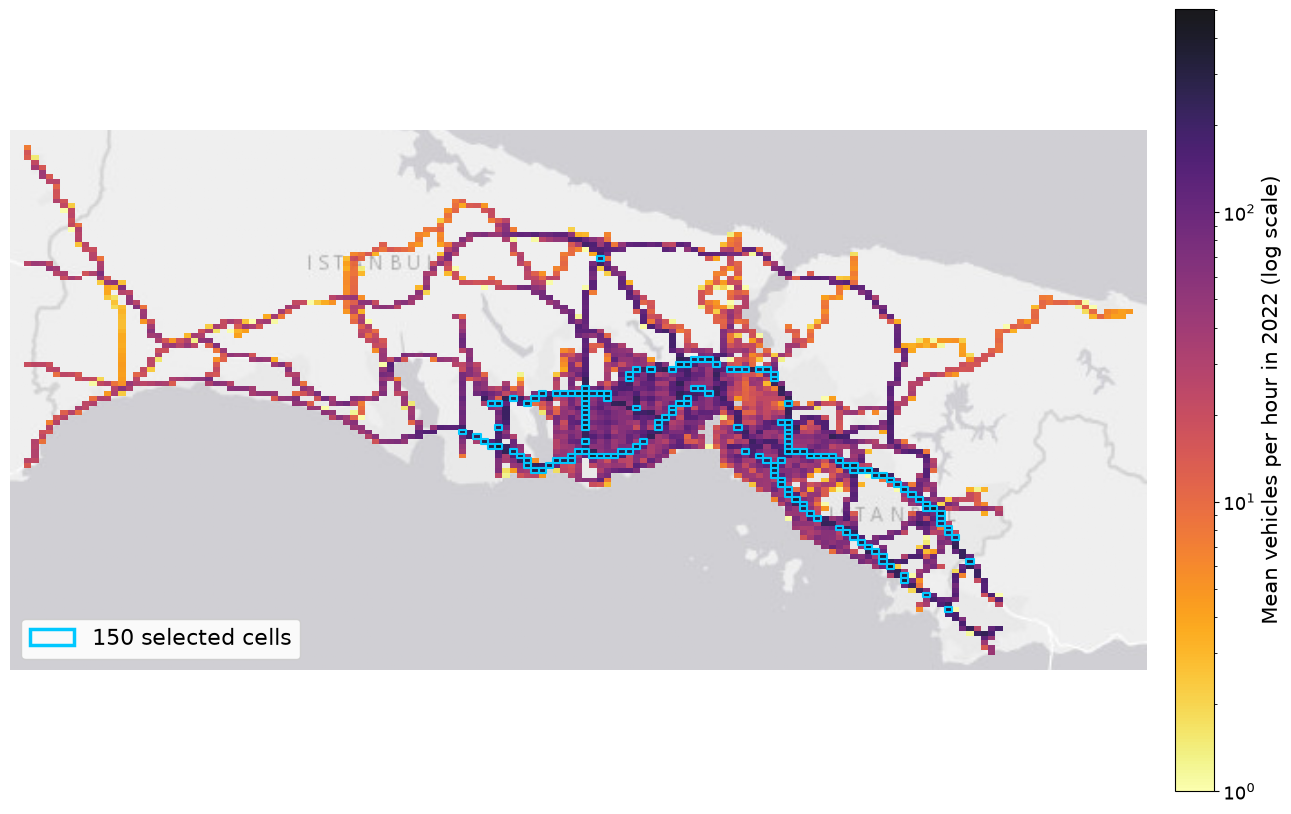

base map: Esri World Light Gray | credit for the caption: Tiles (C) Esri -- Esri, DeLorme, NAVTEQ
| cells drawn: 2459 | selected cells: west of 29.0 E (European side, approx.): 74 | east: 76


In [8]:
# Figure: map of all cells reporting in the selection year (colour = mean vehicles per hour, log scale) with the 150 selected cells outlined
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm
def geohash_box(gh):                                    # lon/lat bounds of one geohash cell
    B32 = '0123456789bcdefghjkmnpqrstuvwxyz'; lon, lat, even = [-180.0, 180.0], [-90.0, 90.0], True
    for ch in gh:
        v = B32.index(ch)
        for bit in (16, 8, 4, 2, 1):
            r = lon if even else lat; mid = (r[0] + r[1]) / 2
            if v & bit: r[0] = mid
            else: r[1] = mid
            even = not even
    return lon[0], lon[1], lat[0], lat[1]
def merc(lon, lat):                                     # lon/lat -> Web Mercator metres (the CRS of the web base map)
    lon, lat = np.asarray(lon, float), np.asarray(lat, float)
    return lon * 20037508.34 / 180, np.log(np.tan((90 + lat) * np.pi / 360)) * 6378137.0
def polys(codes):
    out = []
    for gh in codes:
        x0, x1, y0, y1 = geohash_box(gh); xs, ys = merc([x0, x1, x1, x0], [y0, y0, y1, y1]); out.append(np.c_[xs, ys])
    return out
fig, ax = plt.subplots(figsize=(14, 9.5))
norm = LogNorm(vmin=max(1, cand.mean_vehicles.min()), vmax=cand.mean_vehicles.max())
pc = PolyCollection(polys(cand.cell), array=cand.mean_vehicles.clip(lower=1).values, cmap='inferno_r', norm=norm,
                    edgecolor='none', alpha=0.9, zorder=2); ax.add_collection(pc)
ax.add_collection(PolyCollection(polys(cells.cell), facecolor='none', edgecolor='#00C8FF', linewidth=1.5, zorder=3))
x, y = merc(cand.lon, cand.lat); pad = 3000; ax.set_xlim(x.min() - pad, x.max() + pad); ax.set_ylim(y.min() - pad, y.max() + pad)
BASEMAP, CREDIT = 'none', ''                                        # web base map (needs: pip install contextily, and internet); first provider that works is used
try:
    import contextily as ctx
    for name, src in [('Esri World Light Gray', ctx.providers.Esri.WorldGrayCanvas), ('OpenStreetMap', ctx.providers.OpenStreetMap.Mapnik)]:
        try: ctx.add_basemap(ax, source=src, attribution=False, zorder=1); BASEMAP = name; CREDIT = src.get('attribution', name); break   # credit goes in the figure caption
        except Exception as e: print('base map', name, 'failed:', type(e).__name__)
except ImportError: print('contextily not installed -> map drawn without a base map (pip install contextily)')
ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(pc, ax=ax, shrink=0.85, pad=0.02); cb.set_label(f'Mean vehicles per hour in {SELECT_YEAR} (log scale)', fontsize=15)
cb.ax.tick_params(labelsize=13)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='none', edgecolor='#00C8FF', linewidth=2.5, label=f'{len(cells)} selected cells')],
          loc='lower left', fontsize=16, frameon=True, framealpha=0.9)
fig.tight_layout(); fig.savefig(REPORT / 'fig_map_cells.png', dpi=300, bbox_inches='tight'); plt.show()
print('base map:', BASEMAP, '| credit for the caption:', CREDIT); print( '| cells drawn:', len(cand), '| selected cells: west of 29.0 E (European side, approx.):', int((cells.lon < 29.0).sum()), '| east:', int((cells.lon >= 29.0).sum()))


## Bước 2a. Lịch: nguồn dữ liệu thứ hai

- **Làm gì:** đọc `data/calendar_2022_2025.csv` (ngày lễ, arife, ngày nghỉ bù, tháng Ramadan, nghỉ học, sự kiện đặc biệt; mỗi dòng có cột nguồn và cột `verified`), trải thành bảng theo ngày, tính thêm: tuần trước có phải ngày lễ không, số ngày kể từ ngày lễ gần nhất.
- **Vì sao:** đây là nguồn thứ hai được ghép vào dữ liệu giao thông (yêu cầu Bước 2 của môn). Cờ "tuần trước là lễ" là cơ sở để đo **holiday echo** ở RQ3.
- **Kiểm tra:** các dòng `verified = check` cần đối chiếu nguồn trước khi nộp bài; ô in danh sách này. Bước 2c sẽ tìm thêm các ngày bất thường mà lịch chưa ghi.

In [9]:
cal = pd.read_csv(CAL_FILE, parse_dates=['start_date', 'end_date'])
TYPES = ['holiday', 'arife', 'admin_leave', 'ramadan', 'school_break', 'special_event']
days = pd.DataFrame({'date': pd.date_range(f'{YEARS[0]}-01-01', f'{YEARS[-1]}-12-31', freq='D')})
for t in TYPES:
    s = set()
    for r in cal[cal.event_type == t].itertuples(): s.update(pd.date_range(r.start_date, r.end_date, freq='D'))
    days['is_' + t] = days.date.isin(s).astype('int8')
names = {}
for r in cal[cal.event_type.isin(['holiday', 'arife', 'admin_leave', 'special_event'])].itertuples():
    for d in pd.date_range(r.start_date, r.end_date, freq='D'): names[d] = (names.get(d, '') + ' / ' + r.name).strip(' /')
days['event_name'] = days.date.map(names).fillna('')
days['holiday_like'] = ((days.is_holiday + days.is_arife + days.is_admin_leave) > 0).astype('int8')    # days with holiday traffic
hl = set(days.date[days.holiday_like == 1])
for k, lab in [(7, 'holiday_last_week'), (14, 'holiday_2w'), (21, 'holiday_3w')]:
    days[lab] = (days.date - pd.Timedelta(days=k)).isin(hl).astype('int8')
last = days.date.where(days.holiday_like == 1).ffill()
days['days_since_holiday'] = (days.date - last).dt.days.fillna(60).clip(upper=60).astype('int16')
days['week_after_holiday'] = ((days.holiday_last_week == 1) & (days.holiday_like == 0) & (days.is_special_event == 0)).astype('int8')
dow = days.date.dt.dayofweek
days['day_type'] = np.select([days.is_special_event == 1, days.is_holiday == 1, days.is_arife == 1, days.is_admin_leave == 1, days.week_after_holiday == 1, dow >= 5],
                             ['special_event', 'holiday', 'arife', 'admin_leave', 'week_after_holiday', 'weekend'], 'weekday')
days.to_parquet(PROC / 'calendar_daily.parquet', index=False)
print(days.day_type.value_counts().to_string())
print('\ncalendar rows still to verify (verified = check):'); display(cal[cal.verified != 'yes'][['start_date', 'end_date', 'event_type', 'name']])

day_type
weekday               703
weekend               275
week_after_holiday     51
holiday                41
special_event          15
arife                   8
admin_leave             3

calendar rows still to verify (verified = check):


,start_date,end_date,event_type,name
13,2022-01-22,2022-02-06,school_break,Mid-term break
14,2022-04-09,2022-04-17,school_break,Spring break
15,2022-06-18,2022-09-11,school_break,Summer break
16,2022-11-12,2022-11-20,school_break,Autumn break
17,2022-01-24,2022-01-26,special_event,Heavy snowstorm in Istanbul
18,2022-11-13,2022-11-13,special_event,Istiklal Avenue bombing
60,2023-01-21,2023-02-05,school_break,Mid-term break
61,2023-02-06,2023-02-19,school_break,Schools closed after the 6 February earthquake
62,2023-04-15,2023-04-23,school_break,Spring break
63,2023-06-17,2023-09-10,school_break,Summer break


## Bước 2b. Hàm sửa dữ liệu có công tắc và nhật ký làm sạch

- **Làm gì:** `repair()` có hai công tắc: **gộp trùng** (một dòng cho mỗi ô và giờ) và **lưới giờ đầy đủ** (giờ thiếu thành dòng trống, để lùi một dòng đúng bằng lùi một giờ). Sau đó ghép cờ mất dữ liệu (Bước 1c) và lịch (Bước 2a). Kiểm tra miền giá trị: số xe âm hoặc tốc độ trên 250 km/h bị đặt thành rỗng.
- **Vì sao:** RQ3 đo xem mỗi bước sửa làm sai số đổi bao nhiêu, nên mỗi bước phải bật tắt được. Notebook B có một bản sao của hàm này.
- **Kiểm tra:** mở `report/table_cleaning_log.csv`. Dòng `duplicate groups with identical values` cho biết dòng trùng là bản sao y hệt (gộp bằng trung bình là đúng) hay mâu thuẫn nhau.

In [10]:
raw = pd.read_parquet(PROC / 'traffic_raw.parquet'); raw['ts'] = raw.ts.astype('datetime64[ns]')
bad = (raw.vehicles < 0) | (raw.speed < 0) | (raw.speed > 250)
raw.loc[raw.vehicles < 0, 'vehicles'] = np.nan; raw.loc[(raw.speed < 0) | (raw.speed > 250), 'speed'] = np.nan
dup = raw[raw.duplicated(['cell', 'ts'], keep=False)]
same = int(dup.groupby(['cell', 'ts']).vehicles.nunique().eq(1).sum()) if len(dup) else 0
n_groups = int(dup.groupby(['cell', 'ts']).ngroups) if len(dup) else 0

def repair(d, dedupe=True, grid=True, cells=cells.cell, hours=HOURS):
    d = d.sort_values(['cell', 'ts'], kind='stable')
    if dedupe: d = d.groupby(['cell', 'ts'], as_index=False).agg(vehicles=('vehicles', 'mean'), speed=('speed', 'mean'))
    if grid:                                             # missing hours become empty rows, so one step back is one hour back
        full = pd.MultiIndex.from_product([list(cells), hours], names=['cell', 'ts'])
        d = d.set_index(['cell', 'ts']).reindex(full).reset_index()
    return d.reset_index(drop=True)
# end of repair

df = repair(raw)
df = df.merge(city[['ts', 'cells_reporting', 'city_outage', 'partial_outage', 'value_fault']], on='ts', how='left')
df['date'] = df.ts.dt.normalize(); df = df.merge(days, on='date', how='left')
df['hour'] = df.ts.dt.hour.astype('int8'); df['dow'] = df.ts.dt.dayofweek.astype('int8'); df['weekend'] = (df.dow >= 5).astype('int8')
df['recorded'] = df.vehicles.notna().astype('int8')
df = df.merge(cells[['cell', 'lat', 'lon']], on='cell', how='left')
for c in ['vehicles', 'speed', 'lat', 'lon']: df[c] = df[c].astype('float32')
log = [['monthly files used', len(AVAILABLE)], ['months missing', len(MISSING)], ['rows in the monthly files', RAW_ROWS],
       ['rows with an unparsed timestamp (dropped)', int(inv.ts_unparsed.sum())], ['rows outside the month of their file (dropped)', int(inv.rows_other_month.sum())],
       ['files with swapped lat/lon (fixed)', int(inv.swapped_latlon.astype(bool).sum())], [f'rows of the {len(cells)} selected cells', len(raw)],
       ['rows with values out of range (set empty)', int(bad.sum())], ['rows sharing cell and hour with another row', len(dup)],
       ['duplicate groups', n_groups], ['duplicate groups with identical values', same],
       ['rows after one row per cell and hour', int(raw.drop_duplicates(['cell', 'ts']).shape[0])], ['cell-hours on the full grid', len(df)],
       ['cell-hours without a record', int(df.vehicles.isna().sum())], ['share of cell-hours without a record (%)', round(100 * df.vehicles.isna().mean(), 2)],
       ['city-wide outage hours', int(city.city_outage.sum())], ['partial outage hours', int(city.partial_outage.sum())], ['faulty hours (values far below normal)', int(city.value_fault.sum())],
       ['holiday days', int(days.is_holiday.sum())], ['arife days', int(days.is_arife.sum())], ['bridge (admin leave) days', int(days.is_admin_leave.sum())],
       ['days in the week after a holiday', int(days.week_after_holiday.sum())]]
save(pd.DataFrame(log, columns=['step', 'value']), 'table_cleaning_log.csv'); print(pd.DataFrame(log, columns=['step', 'value']).to_string(index=False))
df.drop(columns=['date']).to_parquet(PROC / 'traffic.parquet', index=False); print(df.shape)

                                          step       value
                            monthly files used       36.00
                                months missing        0.00
                     rows in the monthly files 58393117.00
     rows with an unparsed timestamp (dropped)        0.00
rows outside the month of their file (dropped)        0.00
            files with swapped lat/lon (fixed)        0.00
                rows of the 150 selected cells  3708004.00
     rows with values out of range (set empty)        0.00
   rows sharing cell and hour with another row        0.00
                              duplicate groups        0.00
        duplicate groups with identical values        0.00
          rows after one row per cell and hour  3708004.00
                   cell-hours on the full grid  3945600.00
                   cell-hours without a record   237596.00
      share of cell-hours without a record (%)        6.02
                        city-wide outage hours     1544.

## Bước 2c. Hiểu dữ liệu trước khi đặt câu hỏi

Bốn ô dưới đây trả lời: mục tiêu phân bố ra sao, ô nào thiếu dữ liệu vào lúc nào, và có ngày bất thường nào mà lịch chưa ghi. **Quy tắc:** sau mỗi ô, nhóm viết một câu nhận xét có số vào dòng Nhận xét.

### 2c.1 Thống kê mô tả và phân phối mục tiêu
> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing_pct
vehicles,3708004.0,333.56,188.88,1.0,56.0,206.0,303.0,424.0,942.0,2056.0,6.02
speed,3708004.0,55.17,17.84,2.0,21.0,41.0,55.0,68.0,94.0,158.0,6.02
cells_reporting,3945600.0,2219.93,565.63,0.0,0.0,2337.0,2379.0,2394.0,2417.0,2434.0,0.00


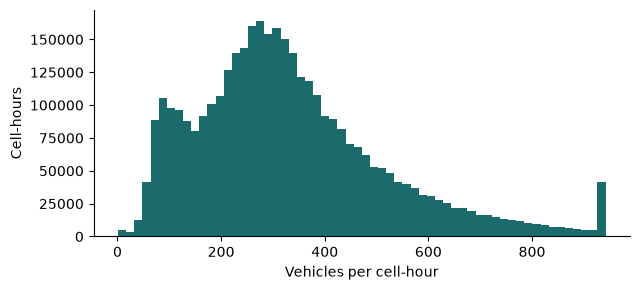

In [11]:
desc = df[['vehicles', 'speed', 'cells_reporting']].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc['missing_pct'] = 100 * df[['vehicles', 'speed', 'cells_reporting']].isna().mean(); save(desc.reset_index().rename(columns={'index': 'column'}), 'table_numeric_summary.csv')
display(desc.round(2))
fig, ax = plt.subplots(figsize=(6.5, 3)); ax.hist(df.vehicles.dropna().clip(upper=df.vehicles.quantile(.99)), bins=60, color='#1B6B6D')
ax.set_xlabel('Vehicles per cell-hour'); ax.set_ylabel('Cell-hours'); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(REPORT / 'fig_eda_target.png', dpi=300); plt.show()

### 2c.2 Độ đầy đủ theo ô và tháng
- **Làm gì:** bản đồ nhiệt tỷ lệ giờ có dữ liệu của 150 ô qua từng tháng.
- **Kiểm tra:** dải trắng ngang là ô hỏng lâu dài; dải trắng dọc là tháng mất dữ liệu toàn thành phố.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

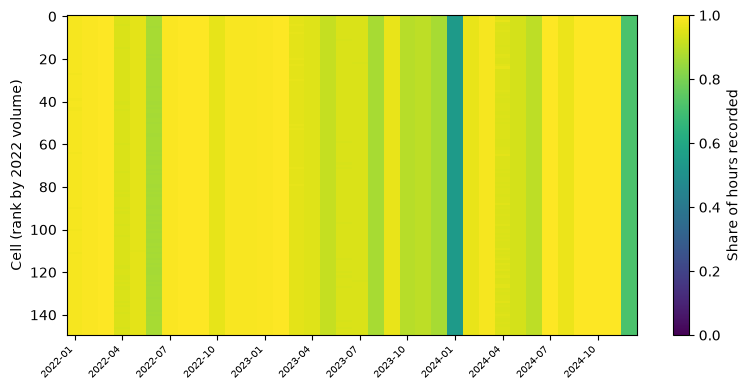

cells with coverage below 50% in at least one month with data: 0 of 150 | months without any data: []


In [12]:
cov = df.groupby(['cell', df.ts.dt.strftime('%Y-%m')]).recorded.mean().unstack()
cov = cov.loc[cells.cell]                                                  # rows in rank order, busiest first
fig, ax = plt.subplots(figsize=(8, 4)); im = ax.imshow(cov.values, aspect='auto', cmap='viridis', vmin=0, vmax=1, interpolation='nearest')
ax.set_xticks(range(0, cov.shape[1], 3)); ax.set_xticklabels(cov.columns[::3], rotation=45, ha='right', fontsize=7)
ax.set_ylabel(f'Cell (rank by {SELECT_YEAR} volume)'); fig.colorbar(im, ax=ax, label='Share of hours recorded'); fig.tight_layout()
fig.savefig(REPORT / 'fig_eda_coverage.png', dpi=300); plt.show()
live = cov.columns[cov.mean() > 0]                                       # months with data somewhere
print('cells with coverage below 50% in at least one month with data:', int((cov[live] < 0.5).any(axis=1).sum()), 'of', len(cov), '| months without any data:', list(cov.columns[cov.mean() == 0]))

### 2c.3 Ngày bất thường mà lịch chưa ghi
- **Làm gì:** chỉ xét ngày có ít nhất 20 giờ dữ liệu; so lượng xe trung bình mỗi ngày với trung vị của cùng thứ trong 4 tuần quanh đó; liệt kê 25 ngày thấp nhất và cho biết lịch đã ghi ngày đó chưa.
- **Vì sao:** ngày nghỉ bù hoặc sự kiện không có trong lịch sẽ bị tính là ngày thường và làm sai kết quả RQ3. Ngày thấp bất thường mà `event_name` trống thì tra nguồn và bổ sung vào file lịch, rồi chạy lại từ Bước 2a.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [13]:
ok = (df.city_outage == 0) & (df.partial_outage == 0) & (df.value_fault == 0)
_g = df[ok & df.vehicles.notna()].groupby(df.ts.dt.normalize())
daily = _g.vehicles.mean().rename('mean_vehicles').to_frame(); daily['hours'] = _g.hour.nunique()
daily = daily[daily.hours >= 20]                       # FIX: only days with at least 20 hours of data (partial days look low only because of the night hours)
daily['dow'] = daily.index.dayofweek
daily['ref'] = daily.groupby('dow').mean_vehicles.transform(lambda s: s.rolling(9, center=True, min_periods=3).median())
daily['ratio'] = daily.mean_vehicles / daily.ref
anom = daily.nsmallest(25, 'ratio').join(days.set_index('date')[['day_type', 'event_name']]).reset_index().rename(columns={'ts': 'date'})
save(anom.round(3), 'table_anomaly_days.csv'); display(anom.round(3))
print('low days (ratio < 0.8) not in the calendar:', int(((anom.ratio < 0.8) & (anom.event_name == '')).sum()), '-> check the news and add them to the calendar file')

,date,mean_vehicles,hours,dow,ref,ratio,day_type,event_name
0,2024-06-17,220.156998,24,0,495.921,0.444,holiday,Kurban Bayrami
1,2024-04-11,224.093002,24,3,503.999,0.445,holiday,Ramazan Bayrami
2,2024-04-10,221.718002,24,2,496.772,0.446,holiday,Ramazan Bayrami
3,2024-06-18,215.809006,24,1,483.166,0.447,holiday,Kurban Bayrami
4,2024-06-19,231.313995,24,2,501.142,0.462,holiday,Kurban Bayrami
5,2024-04-12,241.600998,24,4,509.653,0.474,holiday,Ramazan Bayrami
6,2022-05-03,209.076996,24,1,356.593,0.586,holiday,Ramazan Bayrami
7,2022-07-12,202.634995,24,1,339.581,0.597,holiday,Kurban Bayrami
8,2022-07-11,196.216003,24,0,324.564,0.605,holiday,Kurban Bayrami
9,2022-05-02,205.059006,24,0,336.296,0.610,holiday,Ramazan Bayrami


low days (ratio < 0.8) not in the calendar: 4 -> check the news and add them to the calendar file


### 2c.4 Mục tiêu theo loại ngày và theo năm
> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [14]:
grp = df[ok].groupby([df.ts.dt.year.rename('year'), 'day_type']).vehicles.agg(['mean', 'median', 'std', 'count']).round(1)
save(grp.reset_index(), 'table_eda_by_group.csv'); display(grp)

mean  median         std   count
year day_type                                                  
2022 arife               314.899994   300.0  132.399994    6450
     holiday             238.399994   238.0  108.599998   50100
     special_event       257.299988   243.0  164.800003   14250
     week_after_holiday  314.100006   307.0  148.300003   51450
     weekday             329.899994   325.0  156.699997  833250
     weekend             265.200012   261.0  117.900002  321750
2023 arife               269.700012   263.0  114.300003   10350
     holiday             231.399994   235.0   95.400002   45898
     special_event       273.600006   262.0  131.100006   36000
     week_after_holiday  271.399994   258.0  128.100006   56250
     weekday             287.399994   277.0  139.100006  784050
     weekend             257.799988   252.0  112.300003  289950
2024 admin_leave         371.200012   364.0  180.300003   10800
     arife               345.200012   331.0  165.500000   10800
     holiday             276.399994   263.0  132.899994   50400
     special_event       237.300003   240.0   99.199997    3600
     week_after_holiday  445.899994   423.0  252.199997   64650
     weekday             473.600006   467.0  254.399994  742350
     weekend             319.000000   301.0  156.100006  316650

### 2c.5 Mức xe theo tháng và điểm gãy dữ liệu

- **Làm gì:** lượng xe trung bình ngày thường và tỷ lệ cuối tuần / ngày thường theo từng tháng; đánh dấu các tháng sau `BREAK_DATE`.
- **Vì sao:** từ khoảng 24/01/2024 lượng xe ngày thường tăng khoảng 75% và tỷ lệ cuối tuần giảm từ khoảng 0,9 xuống 0,65 chỉ sau một tuần; giao thông thật không đổi nhanh như vậy, nhiều khả năng cách thu thập số liệu đã đổi (giả thuyết, chưa có tài liệu của IBB). Bài báo cáo đây là một lỗi dữ liệu; Notebook B báo thêm kết quả khi bỏ quý 2024-Q1.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [15]:
okm = ok & df.vehicles.notna()
lvl = df[okm].groupby(df.ts.dt.strftime('%Y-%m')).apply(lambda g: pd.Series({
    'weekday_mean': g.vehicles[g.day_type == 'weekday'].mean(), 'weekend_over_weekday': g.vehicles[g.weekend == 1].mean() / g.vehicles[g.day_type == 'weekday'].mean(),
    'night_3h_mean': g.vehicles[g.hour == 3].mean(), 'peak_8h_mean': g.vehicles[(g.hour == 8) & (g.day_type == 'weekday')].mean()}))
lvl['after_break'] = (pd.to_datetime(lvl.index) + pd.offsets.MonthEnd(0)) >= BREAK_DATE
save(lvl.reset_index().rename(columns={'ts': 'month'}).round(3), 'table_monthly_level.csv'); display(lvl.round(2))
b0 = df[okm & (df.ts < BREAK_DATE) & (df.ts >= BREAK_DATE - pd.Timedelta(days=60)) & (df.day_type == 'weekday')].vehicles.mean()
b1 = df[okm & (df.ts >= BREAK_DATE) & (df.ts < BREAK_DATE + pd.Timedelta(days=60)) & (df.day_type == 'weekday')].vehicles.mean()
print(f'weekday mean 60 days before {BREAK_DATE.date()}: {b0:.1f} | 60 days after: {b1:.1f} | change {100 * (b1 / b0 - 1):+.1f}%')

,weekday_mean,weekend_over_weekday,night_3h_mean,peak_8h_mean,after_break
ts,,,,,
2022-01,335.250000,0.71,73.660004,400.510010,False
2022-02,307.649994,0.73,77.150002,367.019989,False
2022-03,363.829987,0.73,79.500000,451.679993,False
2022-04,340.839996,0.79,86.250000,412.369995,False
2022-05,349.160004,0.77,85.309998,403.200012,False
2022-06,338.549988,0.85,92.320000,391.519989,False
2022-07,319.510010,0.76,90.339996,399.660004,False
2022-08,345.119995,0.83,96.120003,431.850006,False
2022-09,321.100006,0.88,92.650002,368.350006,False


weekday mean 60 days before 2024-01-24: 271.6 | 60 days after: 491.8 | change +81.1%


## Bước 3. Truy vấn bằng SQL (RQ1) và bảng đặc trưng

- **Làm gì:** ghi `sql/queries.sql` gồm: Q1 hồ sơ theo giờ và loại ngày; Q2 lượng xe theo loại ngày và năm, so với ngày thường; Q3 độ đầy đủ và giờ mất dữ liệu theo tháng; Q4 ô bị thưa dần theo quý; Q5 **mô tả holiday echo**: lượng xe của cùng giờ tuần trước so với hôm nay; Q6 bảng đặc trưng bằng `LAG`/`LEAD` trên lưới giờ; Q7 kiểm tra chất lượng bảng đặc trưng.
- **Vì sao:** SQL trả lời RQ1 bằng con số và tạo đặc trưng không rò rỉ (LAG chỉ nhìn quá khứ, LEAD tạo mục tiêu); đây là phần chấm tiêu chí *Analysis with SQL*.
- **Kiểm tra:** mỗi truy vấn in kết quả và lưu `report/table_q*.csv`. Q7 phải in `max_gap_hours = 1` và `dup_keys = 0`.
- **Sửa:** mọi truy vấn bỏ giờ có giá trị sai (`value_fault`); Q2 tách 2024 thành trước và sau điểm gãy; trong Q6, `is_arife_y` chỉ bằng 1 từ 13:00 (arife chỉ nghỉ buổi chiều; giả định theo quy định khu vực công).


In [16]:
SQL = r"""-- sql/queries.sql, written and run by Notebook A
CREATE OR REPLACE TABLE tr AS SELECT * FROM 'data/processed/traffic.parquet';
-- Q1: hourly profile by day type
SELECT hour, day_type, AVG(vehicles) AS mean_vehicles, AVG(speed) AS mean_speed_kmh, COUNT(vehicles) AS cell_hours
FROM tr WHERE city_outage = 0 AND partial_outage = 0 AND value_fault = 0 GROUP BY 1, 2 ORDER BY 2, 1;
-- Q2: mean vehicles by day type and period (years, the 2024 data split at the level break), relative to ordinary weekdays of the same period
WITH m AS (SELECT CASE WHEN ts >= TIMESTAMP '__BREAK__' THEN '2024 after break' WHEN YEAR(ts) = 2024 THEN '2024 before break' ELSE CAST(YEAR(ts) AS VARCHAR) END AS year,
                  day_type, AVG(vehicles) AS mean_vehicles, COUNT(vehicles) AS cell_hours
           FROM tr WHERE city_outage = 0 AND partial_outage = 0 AND value_fault = 0 GROUP BY 1, 2)
SELECT m.*, ROUND(100 * (m.mean_vehicles / w.mean_vehicles - 1), 1) AS pct_vs_weekday
FROM m JOIN (SELECT year, mean_vehicles FROM m WHERE day_type = 'weekday') w USING (year) ORDER BY year, pct_vs_weekday;
-- Q3: completeness and outages by month
SELECT strftime(ts, '%Y-%m') AS month, ROUND(100.0 * AVG(recorded), 2) AS recorded_pct,
       SUM(city_outage) / COUNT(DISTINCT cell) AS city_outage_hours, SUM(partial_outage) / COUNT(DISTINCT cell) AS partial_outage_hours,
       SUM(value_fault) / COUNT(DISTINCT cell) AS faulty_hours
FROM tr GROUP BY 1 ORDER BY 1;
-- Q4: cells thinning out over time, by quarter
WITH c AS (SELECT cell, CONCAT(YEAR(ts), '-Q', QUARTER(ts)) AS quarter, AVG(recorded) AS coverage FROM tr GROUP BY 1, 2)
SELECT quarter, COUNT(*) AS cells, SUM(CASE WHEN coverage >= 0.5 THEN 1 ELSE 0 END) AS cells_with_half_coverage,
       ROUND(AVG(coverage), 3) AS mean_coverage, ROUND(MIN(coverage), 3) AS worst_cell FROM c GROUP BY 1 ORDER BY 1;
-- Q5: holiday echo, described: the same hour one week earlier divided by today, by type of the current day
WITH d AS (SELECT cell, ts, day_type, vehicles, LAG(vehicles, 168) OVER (PARTITION BY cell ORDER BY ts) AS last_week
           FROM tr)
SELECT day_type, COUNT(*) AS cell_hours, ROUND(SUM(last_week) / SUM(vehicles), 3) AS last_week_over_today
FROM d WHERE vehicles IS NOT NULL AND last_week IS NOT NULL GROUP BY 1 ORDER BY 3;
-- Q6: model table on the full hourly grid, target = vehicles in the next hour, every lag is an exact hour lag
CREATE OR REPLACE TABLE feat AS
WITH b AS (
  SELECT cell, ts, lat, lon, vehicles AS volume, speed, city_outage AS outage_now, partial_outage AS partial_now, value_fault AS fault_now,
         LEAD(vehicles, 1) OVER w AS y, LEAD(ts, 1) OVER w AS ts_y,
         LEAD(city_outage, 1) OVER w AS outage_y, LEAD(partial_outage, 1) OVER w AS partial_y, LEAD(value_fault, 1) OVER w AS fault_y,
         LAG(vehicles, 1) OVER w AS lag1, LAG(vehicles, 2) OVER w AS lag2,
         LAG(vehicles, 23) OVER w AS lag23,                      -- same hour yesterday (24 h before the target)
         LAG(vehicles, 167) OVER w AS lag167,                    -- same hour last week (168 h before the target)
         LAG(vehicles, 335) OVER w AS lag335,                    -- two weeks before the target
         LAG(vehicles, 503) OVER w AS lag503,                    -- three weeks before the target
         ts - LAG(ts, 1) OVER w AS gap
  FROM tr WINDOW w AS (PARTITION BY cell ORDER BY ts))
SELECT b.*, HOUR(b.ts_y) AS hour_y, SIN(2 * PI() * HOUR(b.ts_y) / 24) AS hour_sin, COS(2 * PI() * HOUR(b.ts_y) / 24) AS hour_cos,
       ISODOW(b.ts_y) - 1 AS dow_y, CASE WHEN ISODOW(b.ts_y) >= 6 THEN 1 ELSE 0 END AS is_weekend_y,
       CONCAT(YEAR(b.ts), '-Q', QUARTER(b.ts)) AS quarter,
       c.is_holiday AS is_holiday_y, CASE WHEN HOUR(b.ts_y) >= 13 THEN c.is_arife ELSE 0 END AS is_arife_y,   -- FIX: arife is a holiday from 13:00 only
       c.is_admin_leave AS is_admin_leave_y, c.is_ramadan AS is_ramadan_y,
       c.is_school_break AS is_school_break_y, c.is_special_event AS is_special_event_y, c.holiday_like AS holiday_like_y,
       c.holiday_last_week AS holiday_last_week_y, c.holiday_2w AS holiday_2w_y, c.holiday_3w AS holiday_3w_y,
       c.days_since_holiday AS days_since_holiday_y, c.day_type AS day_type_y
FROM b LEFT JOIN 'data/processed/calendar_daily.parquet' c ON CAST(b.ts_y AS DATE) = CAST(c.date AS DATE)
WHERE b.ts_y IS NOT NULL;
-- Q7: quality of the model table
SELECT COUNT(*) AS rows, COUNT(DISTINCT cell) AS cells, MIN(ts) AS first_ts, MAX(ts) AS last_ts,
       MAX(EXTRACT(EPOCH FROM gap)) / 3600 AS max_gap_hours, COUNT(*) - COUNT(DISTINCT cell || CAST(ts AS VARCHAR)) AS dup_keys,
       ROUND(100.0 * AVG(CASE WHEN y IS NULL THEN 1 ELSE 0 END), 2) AS target_missing_pct FROM feat;
"""
SQL = SQL.replace('__BREAK__', str(BREAK_DATE.date()))
(SQLDIR / 'queries.sql').write_text(SQL, encoding='utf-8')
statements = [s.strip() for s in re.split(r';[ \t]*\n', SQL) if s.strip() and not all(l.strip().startswith('--') or not l.strip() for l in s.strip().splitlines())]
qn = 0
for s in statements:
    title = [l for l in s.splitlines() if l.strip().startswith('-- Q')]
    r = con.execute(s)
    if s.lstrip().upper().startswith(('SELECT', 'WITH', '--')) and 'CREATE' not in s.upper():
        qn = int(re.search(r'Q(\d+)', title[0]).group(1)) if title else qn + 1; out = r.df(); out.to_csv(REPORT / f'table_q{qn}.csv', index=False)
        print('\n' + (title[0].strip() if title else f'Q{qn}')); display(out.head(30))
con.execute(f"COPY feat TO '{(PROC / 'feat.parquet').as_posix()}' (FORMAT PARQUET)")
chk = pd.read_csv(REPORT / f'table_q{qn}.csv').iloc[0]
assert chk.max_gap_hours == 1 and chk.dup_keys == 0, 'the grid is not an exact hourly grid'
print('feat.parquet written:', int(chk.rows), 'rows')


-- Q1: hourly profile by day type


,hour,day_type,mean_vehicles,mean_speed_kmh,cell_hours
0,0,admin_leave,246.357778,66.800000,450
1,1,admin_leave,163.933333,71.348889,450
2,2,admin_leave,110.828889,72.964444,450
3,3,admin_leave,94.137778,73.153333,450
4,4,admin_leave,108.040000,72.204444,450
5,5,admin_leave,219.600000,70.282222,450
6,6,admin_leave,491.591111,68.346667,450
7,7,admin_leave,633.973333,66.531111,450
8,8,admin_leave,536.977778,65.568889,450
9,9,admin_leave,462.855556,65.262222,450



-- Q2: mean vehicles by day type and period (years, the 2024 data split at the level break), relative to ordinary weekdays of the same period


,year,day_type,mean_vehicles,cell_hours,pct_vs_weekday
0,2022,holiday,238.378703,50100,-27.7
1,2022,special_event,257.313895,14250,-22.0
2,2022,weekend,265.168500,321750,-19.6
3,2022,week_after_holiday,314.099359,51450,-4.8
4,2022,arife,314.886977,6450,-4.5
5,2022,weekday,329.888347,833250,0.0
6,2023,holiday,231.361301,45898,-19.5
7,2023,weekend,257.789722,289950,-10.3
8,2023,arife,269.672174,10350,-6.2
9,2023,week_after_holiday,271.420533,56250,-5.6



-- Q3: completeness and outages by month


...


-- Q5: holiday echo, described: the same hour one week earlier divided by today, by type of the current day


,day_type,cell_hours,last_week_over_today
0,week_after_holiday,170404,0.764
1,weekend,894013,0.992
2,weekday,2216710,1.001
3,special_event,51157,1.081
4,arife,27150,1.220
5,admin_leave,7200,1.347
6,holiday,138000,1.428



-- Q7: quality of the model table


,rows,cells,first_ts,last_ts,max_gap_hours,dup_keys,target_missing_pct
0,3945450,150,2022-01-01,2024-12-31 22:00:00,1.0,0,6.02


feat.parquet written: 3945450 rows


## Bước 5. Hình RQ1

- **Làm gì:** bốn hình: hồ sơ theo giờ của từng loại ngày; lượng xe theo loại ngày so với ngày thường qua ba năm; độ đầy đủ và giờ mất dữ liệu theo tháng; tỷ lệ "cùng giờ tuần trước / hôm nay" theo loại ngày (minh hoạ holiday echo).
- **Kiểm tra:** chữ tiếng Anh, bỏ viền trên và phải, số in đậm trên cột; caption trong bài nêu kết luận.

> **Nhận xét của nhóm cho mỗi hình (bắt buộc, một câu có số):** ...

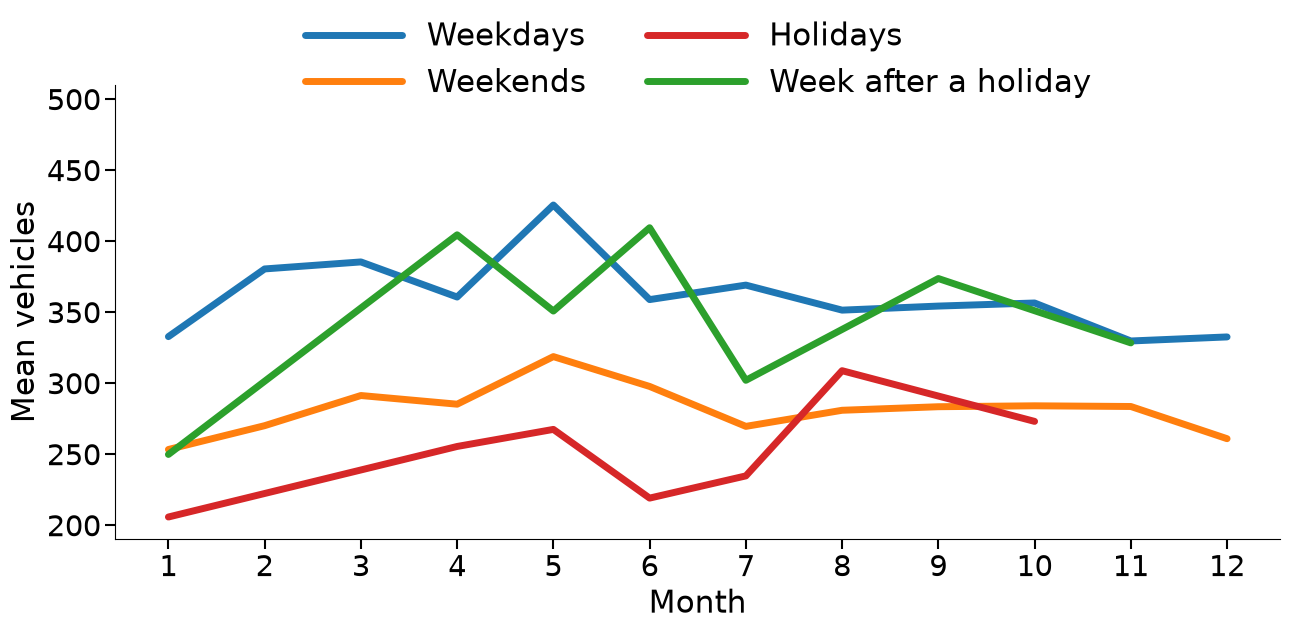

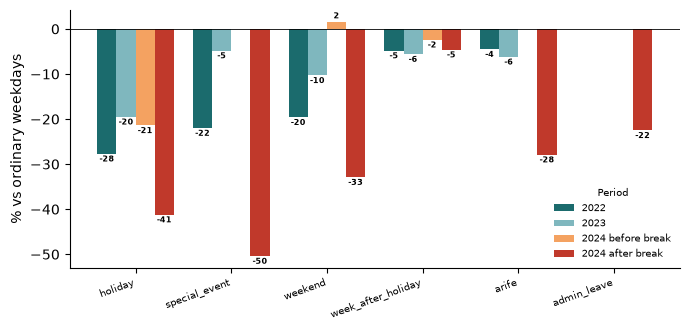

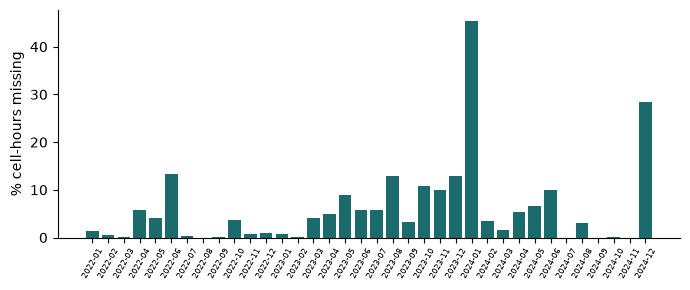

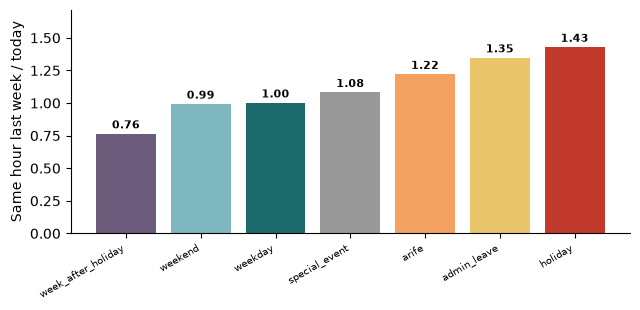

In [17]:
COL = {'weekday': '#1B6B6D', 'weekend': '#7FB7BE', 'holiday': '#C0392B', 'arife': '#F4A261', 'admin_leave': '#E9C46A',
       'week_after_holiday': '#6C5B7B', 'special_event': '#999999'}
def clean(ax): ax.spines[['top', 'right']].set_visible(False)
def bars(labels, values, ylabel, path, fmt='{:.1f}', colors=None):
    fig, ax = plt.subplots(figsize=(6.5, 3.2)); b = ax.bar([str(l) for l in labels], values, color=colors or '#1B6B6D')
    ax.bar_label(b, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8); ax.set_ylabel(ylabel); clean(ax)
    lo, hi = min(0, np.nanmin(values)), np.nanmax(values); ax.set_ylim(lo * 1.2, hi * 1.2 if hi > 0 else 1)
    if len(labels) > 6 or max(len(str(l)) for l in labels) > 12: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

# monthly profile: 4 day types, mean vehicles per cell-hour in each calendar month (2022-2024 pooled; outage and faulty hours left out)
PROF = {'weekday': ('Weekdays', '#1F77B4'), 'weekend': ('Weekends', '#FF7F0E'), 'holiday': ('Holidays', '#D62728'),
        'week_after_holiday': ('Week after a holiday', '#2CA02C')}
okm = (df.city_outage == 0) & (df.partial_outage == 0) & (df.value_fault == 0) & df.vehicles.notna() & df.day_type.isin(list(PROF))
mp = df[okm].assign(month=df.ts.dt.month).groupby(['day_type', 'month']).vehicles.mean().unstack('day_type').reindex(range(1, 13))
save(mp.round(1).reset_index(), 'table_rq1_monthly_profile.csv')
fig, ax = plt.subplots(figsize=(13, 6.5))
for t, (lab, col) in PROF.items():
    s_ = mp[t].dropna(); ax.plot(s_.index, s_.values, lw=5, color=col, label=lab, solid_capstyle='round')   # months without that day type are skipped
lo = np.floor(np.nanmin(mp.values) / 25) * 25; step = np.ceil((np.nanmax(mp.values) - lo) / 6 / 25) * 25
ax.set_yticks(lo + step * np.arange(7)); ax.set_ylim(lo - step * 0.2, lo + step * 6.2)          # 7 marks on the vehicle axis
ax.set_xticks(range(1, 13)); ax.set_xticklabels(range(1, 13), fontsize=21); ax.tick_params(axis='y', labelsize=21)
ax.tick_params(axis='both', length=7, width=1.5)
ax.set_xlabel('Month', fontsize=22); ax.set_ylabel('Mean vehicles', fontsize=22)
ax.legend(frameon=False, fontsize=22, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.2), handlelength=3.2); clean(ax)
fig.tight_layout(); fig.savefig(REPORT / 'fig_rq1_hourly_profile.png', dpi=300, bbox_inches='tight'); plt.show()

q2 = pd.read_csv(REPORT / 'table_q2.csv'); q2 = q2[q2.day_type != 'weekday']
fig, ax = plt.subplots(figsize=(7, 3.4)); types = list(q2.day_type.unique()); yrs = sorted(q2.year.astype(str).unique(), key=lambda s: (s[:4], 'after' in s)); q2['year'] = q2.year.astype(str); w = 0.8 / len(yrs)
for i, y in enumerate(yrs):
    g = q2[q2.year == y].set_index('day_type').reindex(types)
    b = ax.bar(np.arange(len(types)) + i * w, g.pct_vs_weekday, w, label=str(y), color=['#1B6B6D', '#7FB7BE', '#F4A261', '#C0392B'][i % 4])
    ax.bar_label(b, fmt='%.0f', fontsize=6, fontweight='bold', padding=1)
ax.axhline(0, color='k', lw=.6); ax.set_xticks(np.arange(len(types)) + w * (len(yrs) - 1) / 2); ax.set_xticklabels(types, fontsize=7, rotation=20, ha='right')
ax.set_ylabel('% vs ordinary weekdays'); ax.legend(frameon=False, fontsize=7, title='Period', title_fontsize=7); clean(ax); fig.tight_layout(); fig.savefig(REPORT / 'fig_rq1_daytype_by_year.png', dpi=300); plt.show()

q3 = pd.read_csv(REPORT / 'table_q3.csv')
fig, ax = plt.subplots(figsize=(7, 3)); ax.bar(q3.month, 100 - q3.recorded_pct, color='#1B6B6D')
ax.set_ylabel('% cell-hours missing'); ax.tick_params(axis='x', labelsize=6, rotation=60); clean(ax)
fig.tight_layout(); fig.savefig(REPORT / 'fig_rq1_completeness.png', dpi=300); plt.show()

q5 = pd.read_csv(REPORT / 'table_q5.csv')
bars(q5.day_type, q5.last_week_over_today, 'Same hour last week / today', REPORT / 'fig_rq1_echo_ratio.png', fmt='{:.2f}',
     colors=[COL.get(t, '#1B6B6D') for t in q5.day_type])

### Hình heatmap giờ × thứ

- **Làm gì:** lượng xe trung bình theo 24 giờ và 7 thứ trong tuần, chỉ ngày thường và cuối tuần (bỏ ngày lễ, giờ mất dữ liệu, giờ có giá trị sai).
- **Lưu ý:** gộp cả trước và sau điểm gãy 24/01/2024 nên mức tuyệt đối chỉ để so tương đối giữa các giờ và các thứ.
- **Kiểm tra:** `report/fig_rq1_heatmap_hour_dow.png` và `table_rq1_heatmap_hour_dow.csv`.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

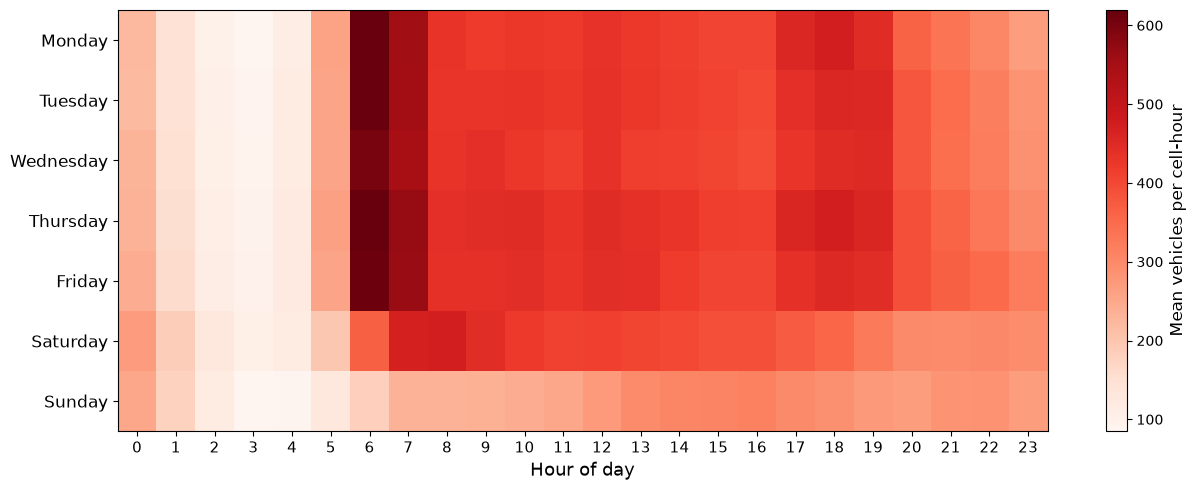

hour,dow,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,0,220.800003,145.199997,98.199997,85.000000,110.400002,256.500000,616.700012,555.700012,431.799988,...,414.000000,405.500000,404.799988,454.700012,472.299988,447.000000,360.899994,332.100006,303.399994,268.500000
1,1,219.000000,144.600006,102.599998,91.000000,115.099998,255.500000,616.900024,553.500000,429.200012,...,415.299988,407.899994,400.000000,441.299988,456.399994,453.799988,381.299988,346.799988,315.700012,281.799988
2,2,229.500000,147.699997,104.199997,92.400002,117.199997,256.000000,599.099976,547.599976,432.899994,...,411.299988,403.000000,395.799988,431.200012,446.700012,448.399994,379.600006,345.700012,319.000000,286.799988
3,3,232.399994,152.699997,107.300003,94.500000,118.900002,260.600006,619.500000,566.900024,441.899994,...,431.200012,414.100006,412.100006,458.399994,472.600006,458.500000,389.000000,359.899994,331.200012,299.200012
4,4,240.199997,158.100006,110.400002,96.800003,120.000000,254.800003,612.099976,564.200012,438.600006,...,418.200012,405.799988,405.700012,438.100006,451.200012,445.299988,388.399994,366.399994,349.899994,319.700012
5,5,270.200012,187.199997,127.900002,105.599998,115.500000,196.800003,366.399994,468.100006,472.200012,...,398.700012,389.799988,388.200012,371.600006,356.299988,324.100006,298.799988,296.200012,300.399994,293.500000
6,6,250.899994,174.899994,113.500000,85.500000,87.300003,129.000000,182.399994,231.899994,232.199997,...,304.500000,307.700012,312.700012,298.399994,288.600006,273.299988,268.299988,282.100006,284.200012,268.299988


In [18]:
# Figure: mean vehicles by hour of day and day of week (ordinary weekdays and weekends only)
okh = (df.city_outage == 0) & (df.partial_outage == 0) & (df.value_fault == 0) & df.day_type.isin(['weekday', 'weekend']) & df.vehicles.notna()
hm = df[okh].groupby(['dow', 'hour']).vehicles.mean().unstack()
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(hm.values, aspect='auto', cmap='Reds')
ax.set_yticks(range(7)); ax.set_yticklabels(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], fontsize=12)
ax.set_xticks(range(24)); ax.set_xticklabels(range(24), fontsize=11); ax.set_xlabel('Hour of day', fontsize=13)
cb = fig.colorbar(im, ax=ax); cb.set_label('Mean vehicles per cell-hour', fontsize=12)
fig.tight_layout(); fig.savefig(REPORT / 'fig_rq1_heatmap_hour_dow.png', dpi=300, bbox_inches='tight'); plt.show()
save(hm.round(1).reset_index(), 'table_rq1_heatmap_hour_dow.csv')

## Bàn giao và test case

- **Làm gì:** kiểm tra tự động các sản phẩm, ghi `manifest.json` (số dòng, mã băm, cấu hình) để Notebook B kiểm tra.
- **Kiểm tra:** ô cuối in `Notebook A: all checks passed`.

In [19]:
def file_md5(p): return md5(p)
f_rows = int(q(f"SELECT COUNT(*) AS n FROM '{(PROC / 'feat.parquet').as_posix()}'").n[0])
assert len(df) == len(cells) * len(HOURS), 'the grid is not complete'
assert not df.duplicated(['cell', 'ts']).any(), 'duplicate keys after repair'
assert df.lat.between(40, 42).all() and df.lon.between(27, 30.5).all(), 'coordinates are not Istanbul'
assert (REPORT / 'table_cleaning_log.csv').exists() and (SQLDIR / 'queries.sql').exists()
manifest = {'config': {'years': YEARS, 'select_year': SELECT_YEAR, 'n_cells': N_CELLS, 'min_coverage': MIN_COVERAGE},
            'months_available': AVAILABLE, 'months_missing': MISSING, 'period': [str(T0), str(T1)], 'feat_rows': f_rows,
            'files': {p: {'rows': int(q(f"SELECT COUNT(*) AS n FROM '{(PROC / p).as_posix()}'").n[0]), 'md5': file_md5(PROC / p)}
                      for p in ['traffic.parquet', 'traffic_raw.parquet', 'feat.parquet', 'calendar_daily.parquet', 'city_hours.parquet']}}
json.dump(manifest, open(PROC / 'manifest.json', 'w'), indent=2); print(json.dumps(manifest['files'], indent=1))
print('Notebook A: all checks passed')

{
 "traffic.parquet": {
  "rows": 3945600,
  "md5": "276d39bb01b0bac4fa0d253db0957a8e"
 },
 "traffic_raw.parquet": {
  "rows": 3708004,
  "md5": "b523393909f191eeaa0ff31dae5481a7"
 },
 "feat.parquet": {
  "rows": 3945450,
  "md5": "ed60ec3d00bd6a353105181a9987a11c"
 },
 "calendar_daily.parquet": {
  "rows": 1096,
  "md5": "29e8018f73568bc79d559035da022716"
 },
 "city_hours.parquet": {
  "rows": 26304,
  "md5": "007ab505a81279c0a4ba6eac01796052"
 }
}
Notebook A: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Số dòng và mã băm khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có (số tháng, số dòng, % giờ thiếu, giờ mất dữ liệu, % giảm lượng xe ngày lễ):
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: